## Setup and load bookcover30 metadata

In [3]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

# Ensure phase2-ai-assisted/ is importable
PHASE2_ROOT = Path.cwd().resolve().parent
if str(PHASE2_ROOT) not in sys.path:
    sys.path.insert(0, str(PHASE2_ROOT))

from src.paths import (
    FEATURES_PARQUET,
    IMAGES_DIR,
    MASKED_IMAGES_DIR,
    SELECTED_6_GENRES,
    TEST_LISTING_CSV,
    TRAIN_LISTING_CSV,
    ensure_dirs,
)
from src.visual_features import (
    extract_visual_attributes,
    init_ocr_reader,
    mask_cover_text,
)

ensure_dirs()

RENAME_MAP = {
    "Amazon Index (ASIN)": "asin",
    "Filename": "filename",
    "Image URL": "image_url",
    "Title": "title",
    "Author": "author",
    "Category ID": "category_id",
    "Category": "genre",
}


def load_listing(csv_path: Path) -> pd.DataFrame:
    df = pd.read_csv(csv_path, sep=";").rename(columns=RENAME_MAP)
    df["image_path"] = df["filename"].apply(lambda name: str(IMAGES_DIR / str(name)))
    df = df[df["image_path"].apply(lambda p: Path(p).is_file())].reset_index(drop=True)
    return df


df_train = load_listing(TRAIN_LISTING_CSV)
df_test = load_listing(TEST_LISTING_CSV)

print(f"Valid train covers: {len(df_train):,} ({df_train['genre'].nunique()} genres)")
print(f"Valid test covers:  {len(df_test):,} ({df_test['genre'].nunique()} genres)")

Valid train covers: 51,300 (30 genres)
Valid test covers:  5,700 (30 genres)


## Align Evaluation Subset (Match Phase 1 or Stratified Sample)

In [14]:
# Optional: align directly with Phase 1's evaluated covers if filename/asin exists in Phase 1 outputs
phase1_neutral_csv = PHASE1_OUTPUTS_DIR / "neutral_predictions.csv"

if phase1_neutral_csv.exists():
    df_p1 = pd.read_csv(phase1_neutral_csv)
    print("Phase 1 neutral_predictions.csv columns:", list(df_p1.columns))

# Sample up to 100 covers per genre across all 30 genres (3,000 covers total)
# Adjust N_PER_GENRE if you want to run on the full 5,700 test set
N_PER_GENRE = 100
df_eval = (
    df_test.groupby("genre", group_keys=False)
    .apply(lambda g: g.sample(n=min(len(g), N_PER_GENRE), random_state=42))
    .reset_index(drop=True)
)
print(f"Selected evaluation set: {len(df_eval):,} covers ({df_eval['genre'].nunique()} genres)")

Phase 1 neutral_predictions.csv columns: ['image', 'true_label', 'predicted_label', 'confidence', 'prompt_style', 'correct']
Selected evaluation set: 0 covers (0 genres)


/var/folders/dg/npvld7kd5xl_h3l33d0lct6r0000gp/T/ipykernel_8687/103360679.py:13: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(n=min(len(g), N_PER_GENRE), random_state=42))


## Build Both Harmonized Evaluation Splits (6-Genre Exact + 30-Genre Test)

In [5]:
# 1. Exact 3,000 covers evaluated by the AI-aided pair in Phase 1
df_6genre = (
    df_train[df_train["genre"].isin(SELECTED_6_GENRES)]
    .groupby("genre", group_keys=False)
    .sample(n=500, random_state=42)
    .reset_index(drop=True)
)
df_6genre["benchmark"] = "6genre_p1_exact"

# 2. Stratified 30-genre test set (100 per genre = 3,000 covers) for Human-only pair alignment
df_30genre = (
    df_test.groupby("genre", group_keys=False)
    .apply(lambda g: g.sample(n=min(len(g), 100), random_state=42))
    .reset_index(drop=True)
)
df_30genre["benchmark"] = "30genre_test"

df_eval = pd.concat([df_6genre, df_30genre], ignore_index=True)
print("Evaluation counts by benchmark:")
print(df_eval["benchmark"].value_counts())

Evaluation counts by benchmark:
benchmark
6genre_p1_exact    3000
30genre_test       3000
Name: count, dtype: int64


/var/folders/dg/npvld7kd5xl_h3l33d0lct6r0000gp/T/ipykernel_8888/1230884890.py:13: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(n=min(len(g), 100), random_state=42))


## Extract Visual Attributes & Create OCR-Masked Covers

In [6]:
# Note: EasyOCR uses CPU/CUDA (falls back cleanly to CPU on macOS if CUDA isn't present)
reader = init_ocr_reader(languages=["en"], gpu=False)

records = []
for row in tqdm(df_eval.itertuples(), total=len(df_eval), desc="Extracting visual & OCR features"):
    src_path = Path(row.image_path)
    masked_path = MASKED_IMAGES_DIR / src_path.name

    vis_attrs = extract_visual_attributes(src_path)
    # Skip re-running EasyOCR if the masked image was already created on an earlier run
    if not masked_path.exists():
        ocr_attrs = mask_cover_text(src_path, masked_path, reader=reader)
    else:
        ocr_attrs = {
            "masked_image_path": str(masked_path),
            "text_area_ratio": float("nan"),
            "ocr_text": "",
        }

    records.append(
        {
            "benchmark": row.benchmark,
            "asin": row.asin,
            "filename": row.filename,
            "genre": row.genre,
            "title": row.title,
            "author": row.author,
            "image_path": str(src_path),
            **vis_attrs,
            **ocr_attrs,
        }
    )

df_features = pd.DataFrame(records)
df_features.to_parquet(FEATURES_PARQUET, index=False)
print(f"Saved {len(df_features):,} rows to {FEATURES_PARQUET}")
df_features.groupby("benchmark")[
    ["mean_brightness", "mean_saturation", "warm_pixel_ratio", "face_count", "text_area_ratio"]
].mean().round(3)

Using CPU. Note: This module is much faster with a GPU.


Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Extracting visual & OCR features:   0%|          | 0/6000 [00:00<?, ?it/s]

/Users/darina/miniconda3/lib/python3.11/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  warnings.warn(warn_msg)

A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Users/darina/miniconda3/lib/python3.11/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/Users/darina/miniconda3/lib/python3.11/site-p

AttributeError: _ARRAY_API not found

ImportError: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for parquet support. Use pip or conda to install pyarrow.
 - Missing optional dependency 'fastparquet'. fastparquet is required for parquet support. Use pip or conda to install fastparquet.

In [7]:
csv_backup = FEATURES_PARQUET.with_suffix(".csv")
df_features.to_csv(csv_backup, index=False)
print(f"Saved {len(df_features):,} rows safely to {csv_backup}")

Saved 6,000 rows safely to /Users/darina/Desktop/JKU_AI_Masterr/YEAR 2/AI & VISUALIZATION/MarshmallowBunnies/phase2-ai-assisted/outputs/visual_features.csv


In [1]:
import sys
from pathlib import Path
import pandas as pd

PHASE2_ROOT = Path.cwd().resolve().parent
if str(PHASE2_ROOT) not in sys.path:
    sys.path.insert(0, str(PHASE2_ROOT))

from src.paths import FEATURES_PARQUET

df_features = pd.read_csv(FEATURES_PARQUET.with_suffix(".csv"))
df_features.to_parquet(FEATURES_PARQUET, index=False)
print("Parquet saved successfully:", FEATURES_PARQUET)

display(
    df_features.groupby("benchmark")[
        ["mean_brightness", "mean_saturation", "warm_pixel_ratio", "face_count", "text_area_ratio"]
    ].mean().round(3)
)

Parquet saved successfully: /Users/darina/Desktop/JKU_AI_Masterr/YEAR 2/AI & VISUALIZATION/MarshmallowBunnies/phase2-ai-assisted/outputs/visual_features.parquet


,mean_brightness,mean_saturation,warm_pixel_ratio,face_count,text_area_ratio
benchmark,,,,,
30genre_test,0.616,0.379,0.320,0.089,0.203
6genre_p1_exact,0.558,0.382,0.364,0.104,0.223


## Visual Sanity Check (Original vs. Text-Masked Covers)

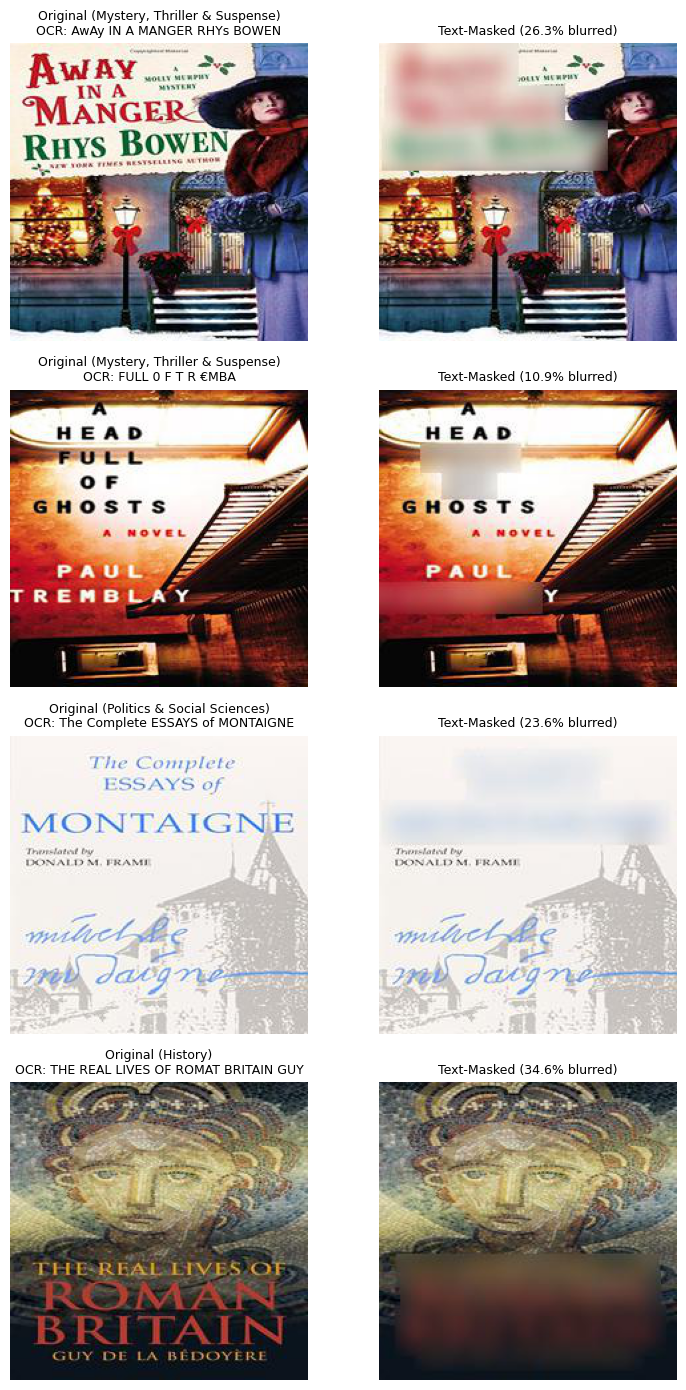

In [4]:
sample_check = df_features[df_features["text_area_ratio"] > 0.03].sample(n=4, random_state=42)

fig, axes = plt.subplots(len(sample_check), 2, figsize=(8, 3.5 * len(sample_check)))
for idx, (_, row) in enumerate(sample_check.iterrows()):
    orig_img = Image.open(row["image_path"])
    mask_img = Image.open(row["masked_image_path"])

    axes[idx, 0].imshow(orig_img)
    axes[idx, 0].set_title(f"Original ({row['genre']})\nOCR: {row['ocr_text'][:35]}", fontsize=9)
    axes[idx, 0].axis("off")

    axes[idx, 1].imshow(mask_img)
    axes[idx, 1].set_title(f"Text-Masked ({row['text_area_ratio']:.1%} blurred)", fontsize=9)
    axes[idx, 1].axis("off")

plt.tight_layout()
plt.show()